# NASA C-MAPSS FD002: Trust-Aware Multimodal RUL Prediction
**Clean, Leak-Free, Modular Pipeline**

This notebook orchestrates the end-to-end Remaining Useful Life (RUL) prediction pipeline on the NASA C-MAPSS FD002 dataset across 7 structured stages:
1. **Setup & Data Ingestion** (Reproducibility lock + dataset loading)
2. **Exploratory Data Analysis** (Engine lifespans, RUL distribution, 6 operating regimes, sensor variance)
3. **Leak-Free Preprocessing & Multimodal Feature Engineering** (Engine-level 80/15/5 split, 3-sigma capping fitted strictly on train, rolling temporal features, PCA visual proxy)
4. **Global Multimodal Regression & Static Fusion** (Modality-specific Random Forests + validation $R^2$ weighting)
5. **Model Diagnostics & Explainability** (Asymmetric NASA scoring, residual analysis, SHAP importance)
6. **TrustGate Adaptive Fusion** (Operating-condition-aware dynamic weighting)
7. **Safety-Critical & Contradiction-Aware Decision Support** (Top-20% high-risk screening, modality disagreement escalation, engine dashboard)

## Part I: Environment Setup & Dataset Ingestion

In [1]:
# 1. Mount Google Drive & Configure Project Path
import os
import sys
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = "/content/drive/MyDrive/FD002 Project"
if PROJECT_DIR not in sys.path:
    sys.path.append(PROJECT_DIR)
os.chdir(PROJECT_DIR)

# 2. Reproducibility Lock
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.config.experimental.enable_op_determinism()

sns.set_theme(style="whitegrid", palette="Set2")
print("✅ Environment initialized and random seeds locked.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Environment initialized and random seeds locked.


In [2]:
# 3. Load FD002 Dataset
from src.data_loader import load_fd002_data
from src.preprocessing import get_useful_sensors, compute_rul_full

train_df, test_df, rul_df = load_fd002_data("data")
train_df = compute_rul_full(train_df)
useful_sensors, dropped_sensors = get_useful_sensors(train_df)

print(f"✅ Training samples: {len(train_df):,} | Engines: {train_df['engine_id'].nunique()}")
print(f"✅ Useful sensors ({len(useful_sensors)}): {useful_sensors}")
print(f"📉 Dropped low-variance sensors: {dropped_sensors}")

✅ Training samples: 53,759 | Engines: 260
✅ Useful sensors (18): ['sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_18', 'sensor_19']
📉 Dropped low-variance sensors: {'invalid_sensors': ['sensor_20', 'sensor_21'], 'low_variance_sensors': ['sensor_16']}


## Part II: Exploratory Data Analysis (FD002 Regimes & Degradation)

Engine Lifetime Summary → Mean: 206.77 | Median: 199.00 | Range: 128–378 cycles | Skewness: 0.98


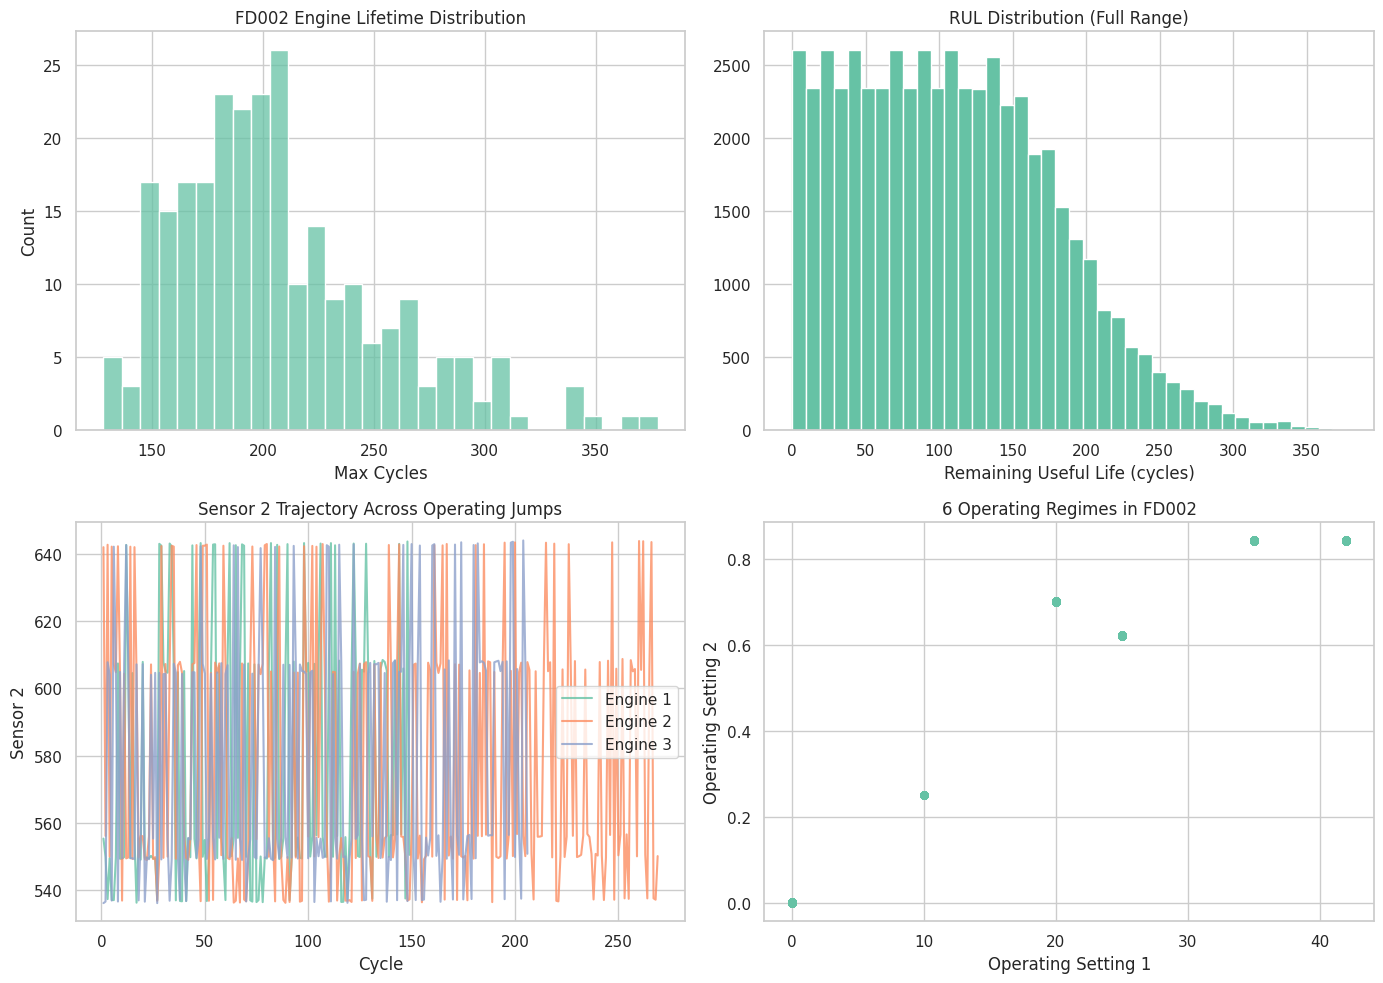

In [3]:
from scipy.stats import skew

engine_life = train_df.groupby('engine_id')['cycle'].max()
print(f"Engine Lifetime Summary → Mean: {engine_life.mean():.2f} | Median: {engine_life.median():.2f} | "
      f"Range: {engine_life.min()}–{engine_life.max()} cycles | Skewness: {skew(engine_life):.2f}")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Engine Lifetime Distribution
sns.histplot(engine_life, bins=30, ax=axes[0, 0])
axes[0, 0].set_title("FD002 Engine Lifetime Distribution")
axes[0, 0].set_xlabel("Max Cycles")

# 2. Full RUL Distribution
axes[0, 1].hist(train_df['RUL'], bins=40, color='#66c2a5', edgecolor='white')
axes[0, 1].set_title("RUL Distribution (Full Range)")
axes[0, 1].set_xlabel("Remaining Useful Life (cycles)")

# 3. Sample Sensor Degradation Trajectory
for eid in train_df['engine_id'].unique()[:3]:
    df_e = train_df[train_df['engine_id'] == eid]
    axes[1, 0].plot(df_e['cycle'], df_e['sensor_2'], label=f'Engine {eid}', alpha=0.8)
axes[1, 0].set_title("Sensor 2 Trajectory Across Operating Jumps")
axes[1, 0].set_xlabel("Cycle")
axes[1, 0].set_ylabel("Sensor 2")
axes[1, 0].legend()

# 4. Six Operating Regimes
axes[1, 1].scatter(train_df['op_setting_1'], train_df['op_setting_2'], s=25, alpha=0.6)
axes[1, 1].set_title("6 Operating Regimes in FD002")
axes[1, 1].set_xlabel("Operating Setting 1")
axes[1, 1].set_ylabel("Operating Setting 2")

plt.tight_layout()
plt.show()

## Part III: Leak-Free Preprocessing & Multimodal Feature Engineering
**Key Fix:** Splitting engines (`80% Train / 15% Val / 5% Test`) *before* fitting 3-sigma outlier bounds and PCA prevents data leakage across splits.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from src.feature_engineering import add_temporal_features, define_modalities

# 1. Engine-Level 80 : 15 : 5 Split (Prevents Data Leakage)
unique_engines = train_df['engine_id'].unique()
train_engines, temp_engines = train_test_split(unique_engines, test_size=0.20, random_state=SEED)
val_engines, test_engines = train_test_split(temp_engines, test_size=0.25, random_state=SEED)

train_mask = train_df['engine_id'].isin(train_engines)
val_mask   = train_df['engine_id'].isin(val_engines)
test_mask  = train_df['engine_id'].isin(test_engines)

print(f"✅ Engine split → Train: {len(train_engines)} | Val: {len(val_engines)} | Test: {len(test_engines)}")

# 2. Leak-Free 3-Sigma Capping (Fit on Train, Apply to All)
train_means = train_df.loc[train_mask, useful_sensors].mean()
train_stds  = train_df.loc[train_mask, useful_sensors].std()
lower_bounds = train_means - 3 * train_stds
upper_bounds = train_means + 3 * train_stds

train_df[useful_sensors] = train_df[useful_sensors].clip(lower_bounds, upper_bounds, axis=1)

# 3. Temporal Features (Per-Engine Rolling Stats & Slope — No Cross-Engine Leakage)
train_df = add_temporal_features(train_df, useful_sensors)

# 4. Leak-Free PCA Visual Proxy (Fit on Train Only, Standardized Feature Names)
N_PCA_COMPONENTS = 2
visual_features = [f"visual_proxy_{i+1}" for i in range(N_PCA_COMPONENTS)]

pca = PCA(n_components=N_PCA_COMPONENTS, random_state=SEED)
pca.fit(train_df.loc[train_mask, useful_sensors])

pca_transformed = pca.transform(train_df[useful_sensors])
for i, col in enumerate(visual_features):
    train_df[col] = pca_transformed[:, i]

print(f"✅ PCA Explained Variance ({N_PCA_COMPONENTS} components): {pca.explained_variance_ratio_.sum()*100:.2f}%")

# 5. Define Multimodal Feature Groups
MODALITIES, ALL_FEATURES = define_modalities(useful_sensors, visual_features)
MODALITIES["visual"] = visual_features  # Enforce consistent naming

X = train_df[ALL_FEATURES].copy()
y = train_df['RUL'].copy()

X_train, y_train = X[train_mask], y[train_mask]
X_val,   y_val   = X[val_mask],   y[val_mask]
X_test,  y_test  = X[test_mask],  y[test_mask]

print(f"🧩 Feature counts → Sensor: {len(MODALITIES['sensor'])} | Visual: {len(MODALITIES['visual'])} | "
      f"Tabular: {len(MODALITIES['tabular'])} | Total: {len(ALL_FEATURES)}")

✅ Engine split → Train: 208 | Val: 39 | Test: 13
✅ PCA Explained Variance (2 components): 99.49%
🧩 Feature counts → Sensor: 72 | Visual: 2 | Tabular: 3 | Total: 77


## Part IV: Global Multimodal RUL Regression & Static Fusion

In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

def nasa_score(y_true, y_pred):
    """NASA C-MAPSS asymmetric scoring (penalizes late predictions exponentially)."""
    d = np.asarray(y_pred) - np.asarray(y_true)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13.0) - 1.0, np.exp(d / 10.0) - 1.0)))

def rul_to_risk(rul, alpha=150, scale=20):
    """Convert RUL cycles into a normalized [0, 1] failure risk score."""
    return 1.0 / (1.0 + np.exp((np.asarray(rul) - alpha) / scale))

# 1. Train Modality-Specific Random Forest Regressors
modality_models = {}
val_predictions = {}
test_predictions = {}

for modality, features in MODALITIES.items():
    rf = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=SEED, n_jobs=-1)
    rf.fit(X_train[features], y_train)

    modality_models[modality]  = rf
    val_predictions[modality]  = rf.predict(X_val[features])
    test_predictions[modality] = rf.predict(X_test[features])

    val_mae = mean_absolute_error(y_val, val_predictions[modality])
    print(f"🌲 {modality:8} modality (VAL) → MAE: {val_mae:.2f} cycles")

# 2. Static Adaptive Fusion (Validation R²-Weighted)
weights = {m: max(0.0, r2_score(y_val, val_predictions[m])) for m in MODALITIES}
total_weight = sum(weights.values()) or len(MODALITIES)
if sum(weights.values()) == 0:
    weights = {m: 1.0 for m in MODALITIES}

y_pred_static = sum((weights[m] / total_weight) * test_predictions[m] for m in MODALITIES)

mae_static = mean_absolute_error(y_test, y_pred_static)
nasa_static = nasa_score(y_test, y_pred_static)

print(f"\n📊 Static R²-Weighted Fusion (TEST) → MAE: {mae_static:.2f} cycles | NASA Score: {nasa_static:,.0f}")

🌲 sensor   modality (VAL) → MAE: 31.07 cycles
🌲 visual   modality (VAL) → MAE: 42.58 cycles
🌲 tabular  modality (VAL) → MAE: 19.56 cycles

📊 Static R²-Weighted Fusion (TEST) → MAE: 24.70 cycles | NASA Score: 234,749


## Part V: Model Diagnostics, Ablation & SHAP Explainability

🎯 FINAL TEST PERFORMANCE (GLOBAL MODEL)
   MAE:        24.70 cycles
   NASA Score: 234,749
   Risk range: [0.018, 0.999]


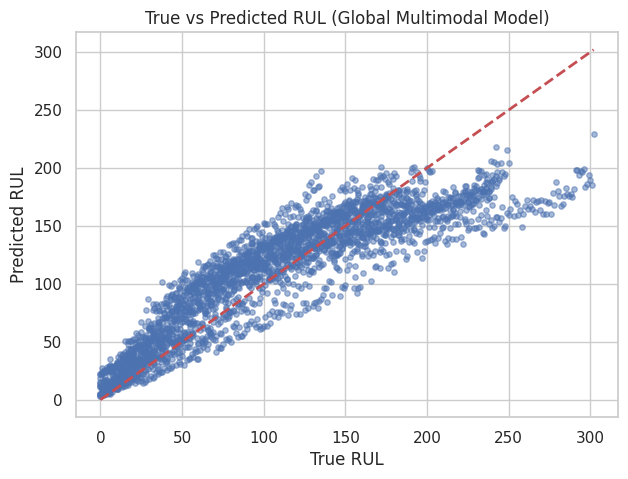

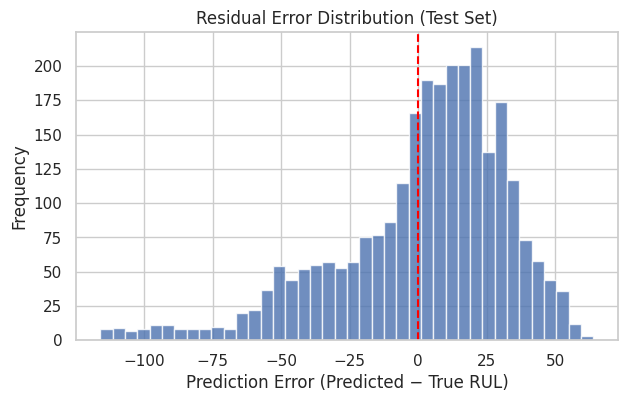

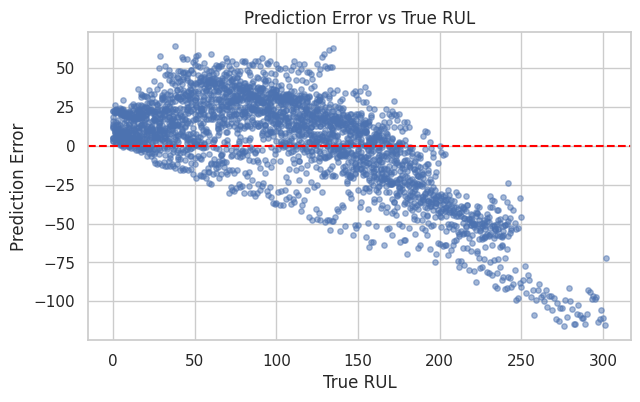

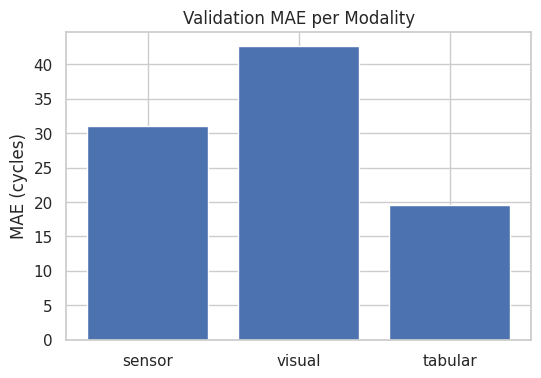

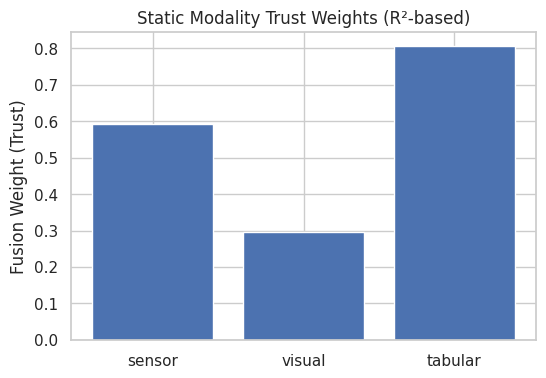

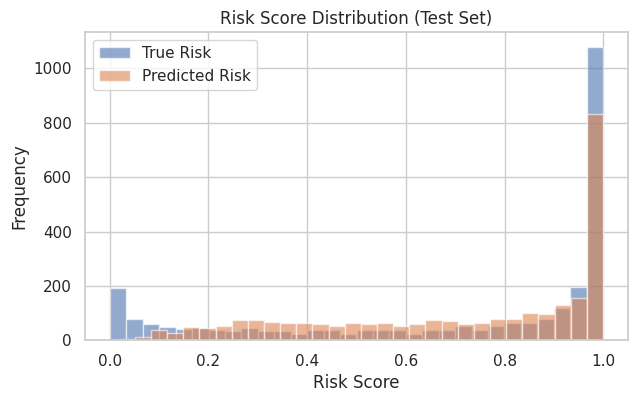


🔍 SHAP Explainability (Sensor Modality – Validation Set)


/content/drive/MyDrive/FD002 Project/src/evaluation.py:143: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_sample, show=False)


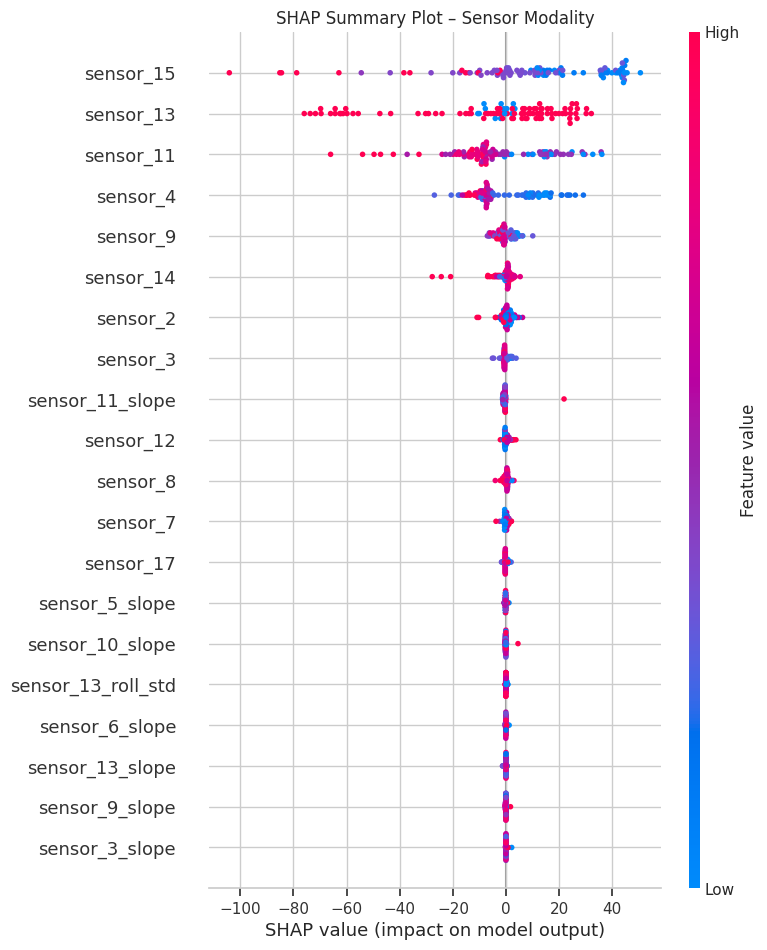

,Rolling Window Size,MAE (Val)
0,5,30.4932
1,10,30.4433
2,20,30.4871
3,30,30.4204


In [10]:
from src.evaluation import run_evaluation
from src.ablation_studies import evaluate_rolling_windows

# 1. Run Diagnostics & SHAP Explainability
run_evaluation(
    y_test=y_test,
    y_pred_fused=y_pred_static,
    y_val=y_val,
    val_predictions=val_predictions,
    MODALITIES=MODALITIES,
    risk_true=rul_to_risk(y_test),
    risk_pred=rul_to_risk(y_pred_static),
    X_val=X_val,
    modality_models=modality_models
)

# 2. Rolling Window Sensitivity Check
window_df = evaluate_rolling_windows(
    train_df=train_df,
    useful_sensors=useful_sensors,
    sensor_features=MODALITIES["sensor"],
    train_engines=train_engines,
    val_engines=val_engines,
    window_sizes=[5, 10, 20, 30]
)
display(window_df.round(4))

## Part VI: TrustGate Context-Aware Adaptive Fusion

Epoch   0 | Loss: 27.2698
Epoch  20 | Loss: 23.1765
Epoch  40 | Loss: 19.7836
Epoch  60 | Loss: 19.2538
Epoch  80 | Loss: 19.0378
✅ TrustGate Adaptive Fusion MAE: 18.68 cycles (vs Static Fusion: 24.70 cycles)


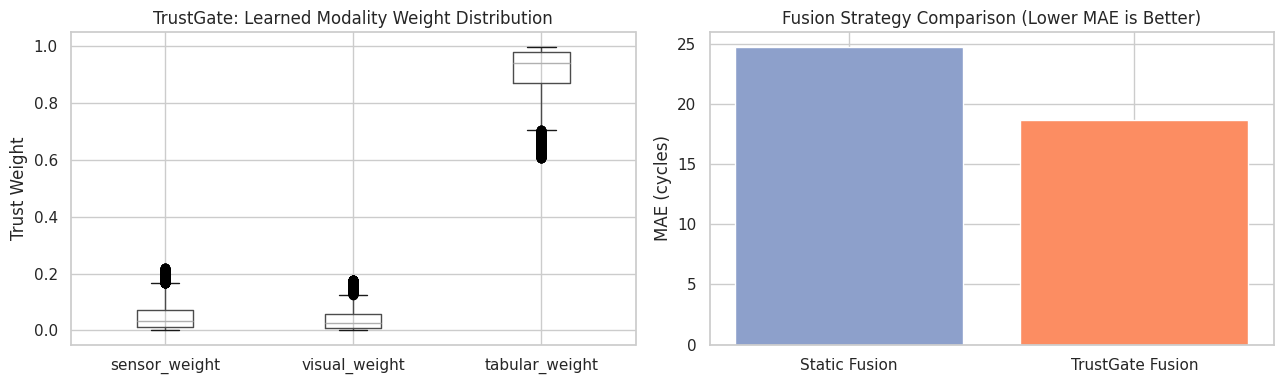

In [11]:
from src.trustgate import train_trustgate

# Train TrustGate adaptive weighting network
trustgate_out = train_trustgate(
    train_df=train_df,
    val_mask=val_mask,
    useful_sensors=useful_sensors,
    MODALITIES=MODALITIES,
    val_predictions=val_predictions,
    y_val=y_val.values
)

mae_trustgate = trustgate_out["mae"]
weight_df = trustgate_out["weights"]
context_df = trustgate_out["context"]

print(f"✅ TrustGate Adaptive Fusion MAE: {mae_trustgate:.2f} cycles (vs Static Fusion: {mae_static:.2f} cycles)")

# Analyze learned trust weights across operating conditions
analysis_df = pd.concat([context_df[['op_setting_1', 'op_setting_2']], weight_df], axis=1)
cond_trust = analysis_df.groupby(['op_setting_1', 'op_setting_2'])[['sensor_weight', 'visual_weight', 'tabular_weight']].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
weight_df.boxplot(ax=axes[0])
axes[0].set_title("TrustGate: Learned Modality Weight Distribution")
axes[0].set_ylabel("Trust Weight")

axes[1].bar(['Static Fusion', 'TrustGate Fusion'], [mae_static, mae_trustgate], color=['#8da0cb', '#fc8d62'])
axes[1].set_title("Fusion Strategy Comparison (Lower MAE is Better)")
axes[1].set_ylabel("MAE (cycles)")

plt.tight_layout()
plt.show()

In [12]:
import torch

def build_trustgate_context(df, useful_sensors, ctx_cols):
    ctx = df.copy()
    # 1. Average short-term sensor reliability per engine
    ctx["avg_reliability"] = (
        ctx.groupby("engine_id")[useful_sensors]
        .transform(lambda x: 1.0 / (1.0 + x.rolling(5, min_periods=1).std().fillna(0)))
        .mean(axis=1)
    )
    # 2. One-hot operating condition columns matching ctx_cols
    op_str = (
        ctx["op_setting_1"].round(1).astype(str)
        + "_"
        + ctx["op_setting_2"].round(1).astype(str)
    )
    for col in ctx_cols:
        if col.startswith("cond_"):
            cond_val = col.replace("cond_", "")
            ctx[col] = (op_str == cond_val).astype(float)
    return ctx[ctx_cols]

In [13]:
tgn_model = trustgate_out["model"]
tgn_scaler = trustgate_out["scaler"]
ctx_cols = trustgate_out["context"].columns.tolist()

X_unseen_df = build_trustgate_context(train_df.loc[test_mask], useful_sensors, ctx_cols)
X_unseen_ctx = torch.FloatTensor(tgn_scaler.transform(X_unseen_df))

tgn_model.eval()
with torch.no_grad():
    unseen_weights = tgn_model(X_unseen_ctx).numpy()

unseen_preds_stack = np.column_stack([test_predictions[m] for m in MODALITIES])
y_pred_tgn_unseen = np.sum(unseen_weights * unseen_preds_stack, axis=1)

mae_tgn_unseen = mean_absolute_error(y_test, y_pred_tgn_unseen)
print(f"🎯 Unseen Held-Out Engines (13 engines) → Static Fusion MAE: {mae_static:.2f} | TrustGate MAE: {mae_tgn_unseen:.2f}")

🎯 Unseen Held-Out Engines (13 engines) → Static Fusion MAE: 24.70 | TrustGate MAE: 19.08


## Part VII: Official Test Set Evaluation, Contradiction Detection & Decision Support
Evaluates the trained pipeline on the official NASA C-MAPSS `test_FD002.txt` last-cycle snapshots using training-set clipping and PCA parameters.

In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from src.contradiction import detect_contradictions

# 1. Preprocess Official Test Set Using Training Parameters (Leak-Free)
test_processed = test_df.copy()
test_processed[useful_sensors] = test_processed[useful_sensors].clip(lower_bounds, upper_bounds, axis=1)
test_processed = add_temporal_features(test_processed, useful_sensors)

pca_test = pca.transform(test_processed[useful_sensors])
for i, col in enumerate(visual_features):
    test_processed[col] = pca_test[:, i]

test_processed['op_cond'] = (
    test_processed[['op_setting_1', 'op_setting_2']]
    .round(1).astype(str).agg('_'.join, axis=1)
)

# Extract last cycle per test engine (official C-MAPSS evaluation protocol)
last_cycle_idx = test_processed.groupby('engine_id')['cycle'].idxmax()
test_last_cycles = test_processed.loc[last_cycle_idx].copy()

# 2. Generate Modality Predictions
test_modality_preds = {
    m: model.predict(test_last_cycles[MODALITIES[m]])
    for m, model in modality_models.items()
}

# 3. Compute Static R²-Weighted Fusion (More robust to mid-life trajectory truncation in test_FD002)
final_predictions = sum((weights[m] / total_weight) * test_modality_preds[m] for m in MODALITIES)

true_rul_values = rul_df['RUL_actual'].values

# 4. Contradiction Detection (50-cycle threshold)
test_contradictions, test_disagreement = detect_contradictions(test_modality_preds, threshold=50)

# 5. Global & Safety-Critical (Top 20% Highest Risk) Evaluation
P = 20
true_threshold = np.percentile(true_rul_values, P)
pred_threshold = np.percentile(final_predictions, P)
high_risk_mask = true_rul_values <= true_threshold

y_true_bin = high_risk_mask.astype(int)
y_pred_bin = (final_predictions <= pred_threshold).astype(int)

summary_df = pd.DataFrame({
    "Evaluation Scope": ["Global (All Test Engines)", f"Safety-Critical (Top {P}% Risk)"],
    "MAE (cycles)": [
        round(mean_absolute_error(true_rul_values, final_predictions), 2),
        round(mean_absolute_error(true_rul_values[high_risk_mask], final_predictions[high_risk_mask]), 2)
    ],
    "NASA Score": [
        int(nasa_score(true_rul_values, final_predictions)),
        int(nasa_score(true_rul_values[high_risk_mask], final_predictions[high_risk_mask]))
    ]
})

print("📊 OFFICIAL TEST PERFORMANCE SUMMARY (STATIC MULTIMODAL FUSION)")
display(summary_df)

print(f"\n🎯 Safety-Screen Classification (Top {P}% Critical Engines):")
print(f"   Accuracy: {accuracy_score(y_true_bin, y_pred_bin):.3f} | "
      f"Precision: {precision_score(y_true_bin, y_pred_bin):.3f} | "
      f"Recall: {recall_score(y_true_bin, y_pred_bin):.3f} | "
      f"F1: {f1_score(y_true_bin, y_pred_bin):.3f}")
print(f"⚠️ Contradictions Flagged for Human Review: {test_contradictions.sum()}/{len(test_contradictions)} "
      f"({100 * test_contradictions.mean():.1f}%)")

📊 OFFICIAL TEST PERFORMANCE SUMMARY (STATIC MULTIMODAL FUSION)


,Evaluation Scope,MAE (cycles),NASA Score
0,Global (All Test Engines),35.30,210500
1,Safety-Critical (Top 20% Risk),6.19,52



🎯 Safety-Screen Classification (Top 20% Critical Engines):
   Accuracy: 0.915 | Precision: 0.788 | Recall: 0.788 | F1: 0.788
⚠️ Contradictions Flagged for Human Review: 157/259 (60.6%)


In [15]:
# 4. Human-in-the-Loop Maintenance Decision Table & Dashboard
decision_df = pd.DataFrame({
    "Engine_ID": test_last_cycles['engine_id'].values,
    "Predicted_RUL": np.round(final_predictions, 1),
    "Actual_RUL": true_rul_values,
    "Risk_Score": np.round(rul_to_risk(final_predictions), 3),
    "Modality_Std": np.round(test_disagreement, 1),
    "Decision": np.where(test_contradictions, "ESCALATE TO HUMAN EXPERT", "AUTO-MAINTENANCE DECISION")
})

display(decision_df.head(10))

,Engine_ID,Predicted_RUL,Actual_RUL,Risk_Score,Modality_Std,Decision
0,1,10.1,18,0.999,9.8,AUTO-MAINTENANCE DECISION
1,2,63.4,79,0.987,56.0,ESCALATE TO HUMAN EXPERT
2,3,73.2,106,0.979,64.8,ESCALATE TO HUMAN EXPERT
3,4,64.7,110,0.986,57.4,ESCALATE TO HUMAN EXPERT
4,5,5.2,15,0.999,4.6,AUTO-MAINTENANCE DECISION
5,6,76.1,155,0.976,67.6,ESCALATE TO HUMAN EXPERT
6,7,12.0,6,0.999,10.7,AUTO-MAINTENANCE DECISION
7,8,37.4,90,0.996,45.5,AUTO-MAINTENANCE DECISION
8,9,6.3,11,0.999,5.6,AUTO-MAINTENANCE DECISION
9,10,54.1,79,0.992,50.2,ESCALATE TO HUMAN EXPERT
